<a href="https://colab.research.google.com/github/KarlaMichelleSorianoSanhez/Simulacion-II/blob/main/Movimiento_browniano.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## $\color{#556B2F}{\text{Movimiento browniano }}$

**NOMBRE**: Karla Michelle Soriano Sánchez

**MATERIA**: Simulación II

### $\color{#556B2F}{\text{Actividad 1. Movimiento browniano estándar}}$

Un movimiento browniano estándar $\{W_t:t\geq 0\}$ comienza en
$W_0=0$, tiene trayectorias continuas e incrementos independientes.
Para $0\leq s<t$,

$$
W_t-W_s\sim N(0,t-s).
$$

Para simular sus valores en el intervalo $[0,T]$, dividimos el tiempo
en $n$ partes iguales de longitud $\Delta t=T/n$. Generamos variables
independientes $\xi_i\sim N(0,1)$ y aplicamos la relación

$$
W_{i+1}=W_i+\sqrt{\Delta t}\,\xi_i,
\qquad i=0,\ldots,n-1.
$$

Cada incremento tiene media cero y varianza $\Delta t$. La simulación
produce $n+1$ valores, incluyendo el valor inicial.

#### $\color{#556B2F}{\text{Pseudocódigo}}$

1. Elegir $T>0$ y un entero positivo $n$.
2. Calcular $\Delta t=T/n$.
3. Establecer $W_0=0$ y guardar este valor.
4. Para $i=0,\ldots,n-1$:
   - Generar una variable $\xi_i\sim N(0,1)$ independiente de las anteriores.
   - Calcular $W_{i+1}=W_i+\sqrt{\Delta t}\,\xi_i$.
   - Guardar el nuevo valor.
5. Devolver los valores de la trayectoria.

In [171]:
import random as r              #generar números aleatorios
import numpy as np              #calcular la raíz cuadrada
import matplotlib.pyplot as plt #graficar la trayectoria.



In [172]:
def brown(T, n):
    """Genera una trayectoria browniana estándar en [0, T] con n pasos."""

    dt = T / n       # Tamaño del paso de tiempo
    w_0 = 0          # Valor inicial del movimiento browniano
    lista = [w_0]    # Guardamos la trayectoria comenzando en cero

    for i in range(n):
        dw = r.gauss(0, 1)             # Generamos una normal estándar
        w_1 = w_0 + np.sqrt(dt) * dw   # Sumamos el incremento browniano
        lista.append(w_1)             # Guardamos el nuevo valor
        w_0 = w_1                     # Actualizamos el valor anterior

    return lista

#### $\color{#556B2F}{\text{Simulación de una trayectoria}}$

Simulamos una trayectoria en $[0,1]$ utilizando $n=1000$ pasos.
En este caso,

$$
\Delta t=\frac{1}{1000}=0.001.
$$

Para graficarla, asociamos cada valor $W_i$ con el tiempo
$t_i=i\Delta t$.

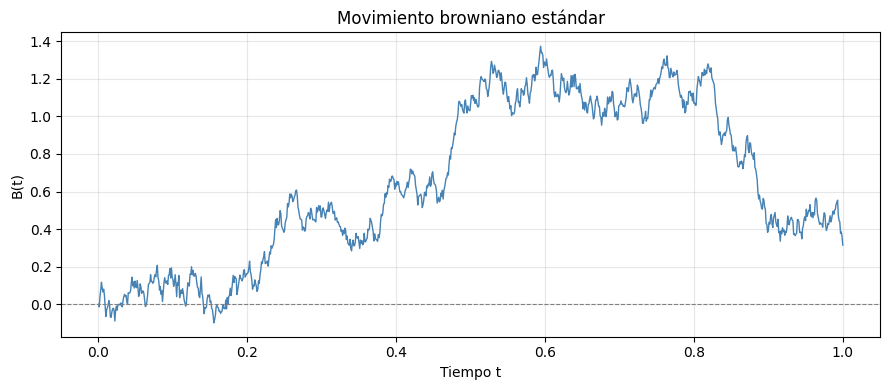

In [173]:
# Elegimos el tiempo final y el número de pasos.
T = 1
n = 1000

# Generamos una trayectoria del movimiento browniano.
B = brown(T, n)

# Creamos los tiempos correspondientes a los n + 1 valores.
t = np.linspace(0, T, n + 1)

# Graficamos la trayectoria.
plt.figure(figsize=(9, 4))
plt.plot(t, B, color="steelblue", linewidth=1)
plt.axhline(0, color="gray", linestyle="--", linewidth=0.8)

plt.title("Movimiento browniano estándar")
plt.xlabel("Tiempo t")
plt.ylabel("B(t)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

La trayectoria comienza en cero y se construye sumando incrementos
aleatorios. Al ejecutar nuevamente el código se obtiene un recorrido
distinto. Los segmentos rectos de la gráfica unen los puntos simulados;
no describen el comportamiento exacto del proceso entre esos tiempos.

### $\color{#556B2F}{\text{Actividad 2. Simulación de 100 trayectorias}}$

Utilizamos la función `brown(T, n)` de la actividad anterior para generar
100 trayectorias independientes en el intervalo $[0,1]$, cada una con
1000 pasos. Todas comienzan en cero y se construyen con nuevos
incrementos normales independientes.

Para el movimiento browniano estándar,

$$
\mathbb{E}[W_t]=0,
\qquad
\operatorname{Var}(W_t)=t.
$$

Por lo tanto, su desviación estándar es $\sqrt{t}$. Agregamos a la
gráfica las funciones

$$
f(t)=\sqrt{t},
\qquad
g(t)=-\sqrt{t},
$$

como referencia para visualizar la dispersión. Estas curvas no son
límites del proceso: las trayectorias pueden cruzarlas.

#### $\color{#556B2F}{\text{Pseudocódigo}}$

1. Elegir la cantidad de trayectorias.
2. Para cada trayectoria:
   - Ejecutar el pseudocódigo browniano implementado en `brown(1, 1000)`.
   - Guardar la trayectoria obtenida.
3. Representar todas las trayectorias en una misma gráfica.
4. Agregar las curvas $\sqrt{t}$ y $-\sqrt{t}$.

In [174]:
def trayectorias(n):
    """Genera n trayectorias brownianas en [0, 1], con 1000 pasos cada una."""

    lista = []  # Guardamos todas las trayectorias

    for i in range(n):
        M = brown(1, 1000)  # Generamos una trayectoria nueva
        lista.append(M)    # La agregamos a la lista

    return lista

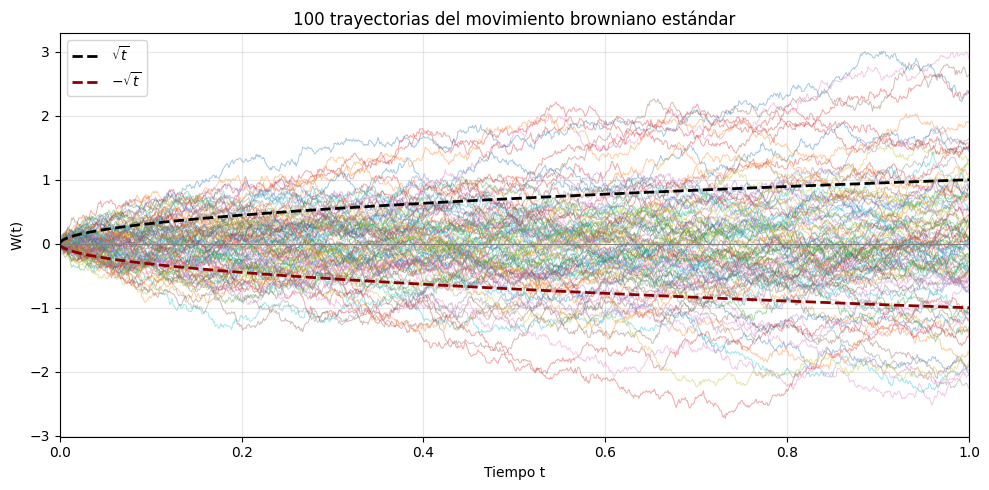

In [175]:
# Generamos 100 trayectorias independientes.
caminos = trayectorias(100)

# Todas utilizan los mismos tiempos.
t = np.linspace(0, 1, 1001)

plt.figure(figsize=(10, 5))

# Dibujamos cada trayectoria en la misma gráfica.
for W in caminos:
    plt.plot(t, W, linewidth=0.7, alpha=0.4)

# Agregamos las curvas de referencia.
plt.plot(t, np.sqrt(t), color="black", linewidth=2,
         linestyle="--", label=r"$\sqrt{t}$")
plt.plot(t, -np.sqrt(t), color="darkred", linewidth=2,
         linestyle="--", label=r"$-\sqrt{t}$")

plt.axhline(0, color="gray", linewidth=0.8)
plt.title("100 trayectorias del movimiento browniano estándar")
plt.xlabel("Tiempo t")
plt.ylabel("W(t)")
plt.xlim(0, 1)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


Las trayectorias parten del mismo punto, pero siguen recorridos distintos.
La varianza $t$ indica que la dispersión del proceso aumenta con el tiempo.
Las curvas $\pm\sqrt{t}$ permiten comparar esa escala de dispersión con
los valores simulados, sin exigir que las trayectorias permanezcan entre ellas.

### $\color{#556B2F}{\text{Actividad 3. Movimiento browniano con deriva}}$


El movimiento browniano con deriva $\mu$ y parámetro de varianza
$\sigma^2$, comenzando en cero, se define como

$$
X_t=\mu t+\sigma W_t,
$$

donde $W_t$ es un movimiento browniano estándar. El término $\mu t$
determina la tendencia media del proceso, mientras que $\sigma$
controla su dispersión.

Como $W_t\sim N(0,t)$, tenemos

$$
X_t\sim N(\mu t,\sigma^2t).
$$

En particular,

$$
E[X_t]=\mu t,
\qquad
\operatorname{Var}(X_t)=\sigma^2t.
$$

Para programarlo, utilizo la función `brown(T, n)` de la Actividad 1.
Primero genero una trayectoria browniana estándar y después aplico
la transformación $X_{t_i}=\mu t_i+\sigma W_{t_i}$ en cada tiempo
$t_i=iT/n$.

La función recibe los parámetros $\mu$, $\sigma$, $T$ y $n$.
El valor inicial es $X_0=0$.

**Pseudocódigo**

1. Recibir $\mu$, $\sigma$, $T$ y $n$.
2. Generar una trayectoria con `brown(T, n)`.
3. Construir los tiempos $t_i=iT/n$, para $i=0,\ldots,n$.
4. Calcular $X_{t_i}=\mu t_i+\sigma W_{t_i}$.
5. Devolver la trayectoria obtenida.

In [176]:
def deriva(mu, sigma, T, n):
    """Genera una trayectoria browniana con deriva que comienza en cero."""
    W = np.array(brown(T, n))     # Genero la trayectoria browniana estándar
    t = np.linspace(0, T, n + 1)  # Divido [0, T] en n intervalos

    X = mu * t + sigma * W        # Aplico la definición de X_t
    return X

#### $\color{#556B2F}{\text{Una trayectoria con deriva}}$

Para observar el comportamiento del proceso, simulo una trayectoria
en $[0,4]$ con $\mu=0.6$ y $\sigma=0.5$.

También grafico la media $E[X_t]=0.6t$ como referencia. Aunque la
media es creciente, la trayectoria puede presentar aumentos y
disminuciones debido a la componente aleatoria.

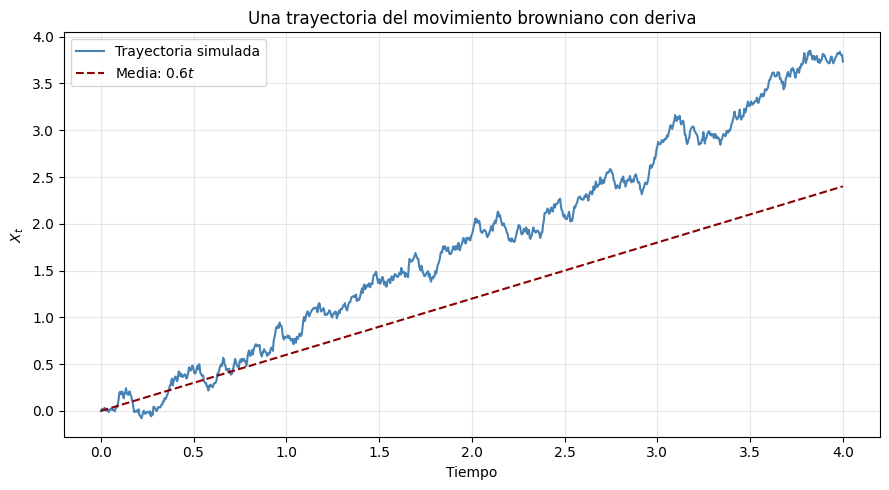

In [177]:
# Fijo los parámetros de la simulación
mu = 0.6
sigma = 0.5
T = 4
n = 1000

r.seed(123)  # Fijo la semilla para poder reproducir los resultados

# Genero los tiempos y una trayectoria
t = np.linspace(0, T, n + 1)
X = deriva(mu, sigma, T, n)

plt.figure(figsize=(9, 5))
plt.plot(t, X, color="steelblue", label="Trayectoria simulada")

# Agrego la media teórica como referencia
plt.plot(t, mu * t, "--", color="darkred", label=r"Media: $0.6t$")

plt.title("Una trayectoria del movimiento browniano con deriva")
plt.xlabel("Tiempo")
plt.ylabel(r"$X_t$")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### $\color{#556B2F}{\text{Simulación de 100 trayectorias}}$

Ahora repito el procedimiento para generar 100 trayectorias
independientes.

Todas comienzan en cero y tienen media $0.6t$. Como su varianza
es $0.25t$, la dispersión alrededor de la media aumenta con el tiempo.

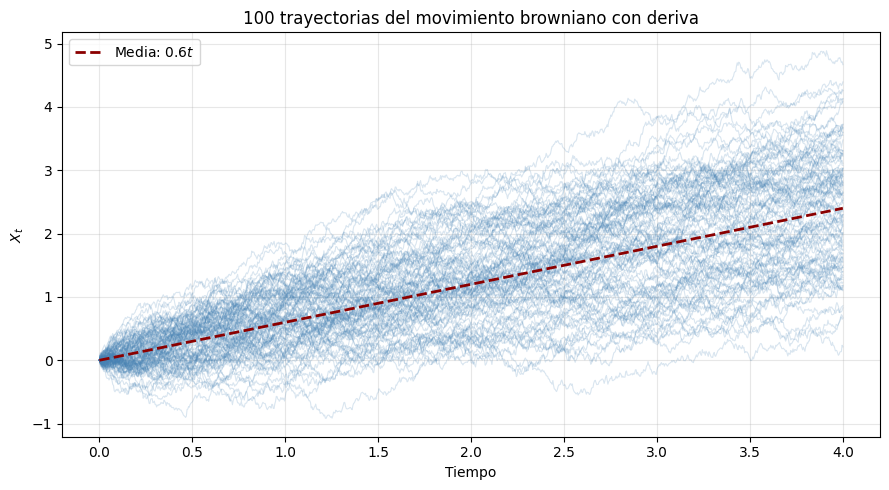

In [178]:
plt.figure(figsize=(9, 5))

# Genero una nueva trayectoria en cada repetición
for i in range(100):
    X = deriva(mu, sigma, T, n)
    plt.plot(t, X, color="steelblue", alpha=0.2, linewidth=0.8)

# Dibujo la media sobre las trayectorias
plt.plot(t, mu * t, "--", color="darkred",
         linewidth=2, label=r"Media: $0.6t$")

plt.title("100 trayectorias del movimiento browniano con deriva")
plt.xlabel("Tiempo")
plt.ylabel(r"$X_t$")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### $\color{#556B2F}{\text{ Ejercicio}}$

**Enunciado.** Encuentre la probabilidad de que el movimiento
browniano con parámetro de deriva $\mu=0.6$ y parámetro de varianza
$\sigma^2=0.25$ tome valores entre $1$ y $3$ al tiempo $4$.
Resolver analíticamente y por simulación.

##### $\color{#556B2F}{\text{Solución analitica }}$
Considero que el proceso comienza en $X_0=0$. La probabilidad
que busco es

$$
P(1\leq X_4\leq3).
$$

Como $\sigma^2=0.25$, entonces $\sigma=0.5$. Sustituyendo en la
definición del proceso,

$$
X_t=0.6t+0.5W_t.
$$

En el tiempo $t=4$,

$$
X_4=2.4+0.5W_4.
$$

Dado que $W_4\sim N(0,4)$, calculo la media y la varianza:

$$
E[X_4]=2.4,
$$

$$
\operatorname{Var}(X_4)=(0.5)^2(4)=1.
$$

Por lo tanto, $X_4\sim N(2.4,1)$. Para calcular la probabilidad,
estandarizo restando la media y dividiendo entre la desviación
estándar, que en este caso es $1$:

$$
P(1\leq X_4\leq3)
=
P\left(
\frac{1-2.4}{1}\leq Z\leq\frac{3-2.4}{1}
\right),
$$

donde $Z\sim N(0,1)$. Así,

$$
P(1\leq X_4\leq3)=P(-1.4\leq Z\leq0.6).
$$

Usando la función de distribución normal estándar $\Phi$, obtengo

$$
P(1\leq X_4\leq3)=\Phi(0.6)-\Phi(-1.4).
$$

Entonces,

$$
\boxed{P(1\leq X_4\leq3)\approx0.64499.}
$$

In [179]:
from math import erf, sqrt

def Phi(z):
    """Calcula la función de distribución normal estándar."""
    return 0.5 * (1 + erf(z / sqrt(2)))


# Evalúa la expresión de la solución analítica
p_analitica = Phi(0.6) - Phi(-1.4)

print(f"Probabilidad analítica: {p_analitica:.5f}")

Probabilidad analítica: 0.64499


##### $\color{#556B2F}{\text{ Solución por simulación}}$

Para estimar la misma probabilidad, genero $N$ trayectorias
independientes en $[0,4]$ y reviso el último valor de cada una.

Si $M$ trayectorias terminan dentro de $[1,3]$, calculo la proporción

$$
\widehat{p}=\frac{M}{N}.
$$

Esta proporción es el promedio de los indicadores del evento
$1\leq X_4\leq3$. Por la ley de los grandes números, converge
a la probabilidad buscada cuando aumenta $N$.

En el conteo solo considero el valor en $t=4$, porque el ejercicio
no pide que el proceso permanezca dentro del intervalo durante
toda la trayectoria.

**Pseudocódigo**

1. Fijar $N$ e iniciar el contador $M=0$.
2. Generar una trayectoria con `deriva(mu, sigma, T, n)`.
3. Obtener su último valor.
4. Si pertenece a $[1,3]$, aumentar $M$ en uno.
5. Repetir hasta completar las $N$ trayectorias.
6. Calcular $M/N$.

In [180]:
def probabilidad_deriva(mu, sigma, T, n, N, a, b):
    """Estima la probabilidad de que X_T esté entre a y b."""
    contador = 0

    for i in range(N):
        X = deriva(mu, sigma, T, n)  # Genero una trayectoria independiente
        valor_final = X[-1]         # Tomo el valor en el tiempo T

        # Cuento las trayectorias que terminan dentro del intervalo
        if a <= valor_final <= b:
            contador += 1

    return contador / N

In [181]:
# Uso los parámetros del ejercicio
mu = 0.6
sigma = 0.5          # La desviación por unidad de tiempo es sqrt(0.25)
T = 4
n = 100             # Pasos de cada trayectoria
N = 10000           # Trayectorias para estimar la probabilidad

r.seed(123)          # Hago reproducible este cálculo

# Estimo la probabilidad de que el valor final esté entre 1 y 3
p_simulada = probabilidad_deriva(mu, sigma, T, n, N, 1, 3)

# Calculo la diferencia respecto al resultado analítico
diferencia = abs(p_simulada - p_analitica)

print(f"Probabilidad analítica: {p_analitica:.5f}")
print(f"Probabilidad simulada:  {p_simulada:.5f}")
print(f"Diferencia absoluta:   {diferencia:.5f}")

Probabilidad analítica: 0.64499
Probabilidad simulada:  0.64610
Diferencia absoluta:   0.00111




Analíticamente obtuve que la probabilidad de que $X_4$ esté entre
$1$ y $3$ es aproximadamente $64.5\%$. Por simulación, estimé
esta probabilidad contando los valores finales que pertenecen
al intervalo y dividiendo entre las $10\,000$ trayectorias.

La diferencia calculada corresponde al error de Monte Carlo,
debido al uso de una muestra finita. Al aumentar el número de
trayectorias, disminuye el tamaño típico de este error.

Para la estimación utilicé 100 pasos por trayectoria. Esto conserva
la distribución correcta de $X_4$, ya que `brown` genera incrementos
normales con la varianza correspondiente. Usar más pasos permite
dibujar la trayectoria con mayor detalle, pero no mejora la
distribución de su valor final.